<a href="https://colab.research.google.com/github/arif18-tech/TinyML/blob/main/Lec_05_TensorflowLite_Converter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

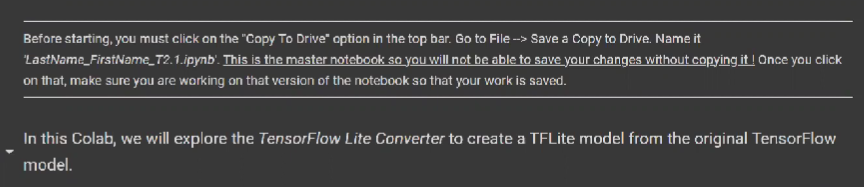

In [ ]:
try:
  %tensorflow_vesion 2.x
except Exception:
  pass

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

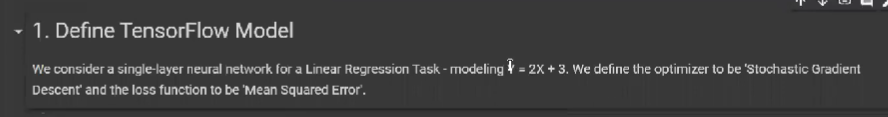

In [ ]:
my_layer = Dense(units=1, input_shape=[1])
model= Sequential([my_layer])
OPT='sgd'
LOSS='mean_squared_error'
model.compile(optimizer=OPT, loss=LOSS)
xs=np.array([-1.0, 0.0, 1.0, 2.0, 3.0, 4.0], dtype=float)
ys=np.array([1.0, 3.0, 5.0, 7.0, 9.0, 11.0], dtype=float)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


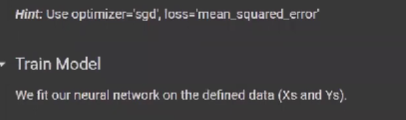

In [ ]:
model.fit(xs,ys,epochs=500)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - loss: 80.6973
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 63.8662
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 50.6166
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 40.1849
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 31.9703
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 25.5001
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - loss: 20.4026
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 16.3851
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 13.2175
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 10.7186
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 8.7461
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 7.1878
Epoch 13/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - loss: 5.9555
Epoch 14/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - loss: 4.9798
Epoch 15/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 4.2061
Epoch

In [ ]:
print(model.predict(np.array([10.0])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
[[23.023022]]


In [ ]:
print("here are the parameters that the model learned: {}".format(my_layer.get_weights()))

here are the parameters that the model learned: [array([[2.0033367]], dtype=float32), array([2.989655], dtype=float32)]


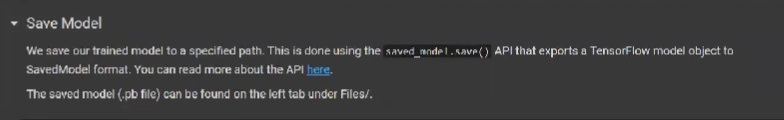

In [ ]:
export_dir='saved_TF_model/model1' #folder path
tf.saved_model.save(model, export_dir)

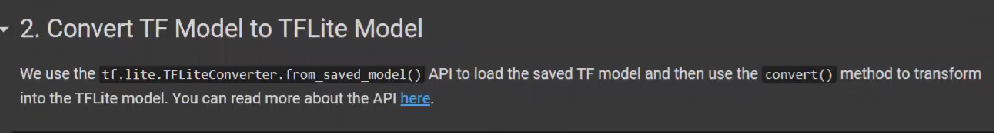

In [ ]:
#convert the model
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

Saved artifact at '/tmp/tmpb10ciq_o'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor_2')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140034824940112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034824940304: TensorSpec(shape=(), dtype=tf.resource, name=None)


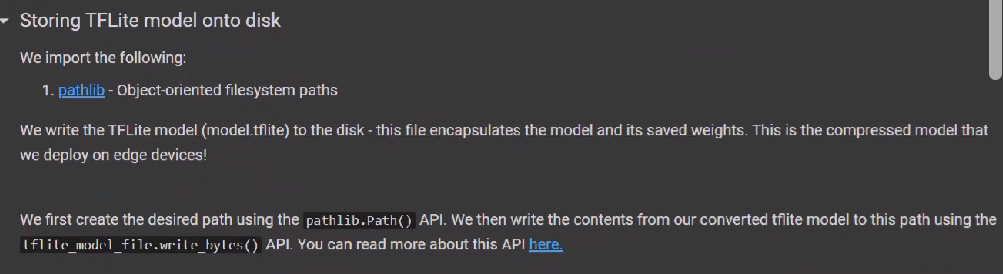

In [ ]:
import pathlib

tflite_model_file = pathlib.Path('model.tflite')
tflite_model_file.write_bytes(tflite_model)

1104

In [ ]:
print("size of Tensorflow Lite model in bytes: ", tflite_model_file.write_bytes(tflite_model))

size of Tensorflow Lite model in bytes:  1104


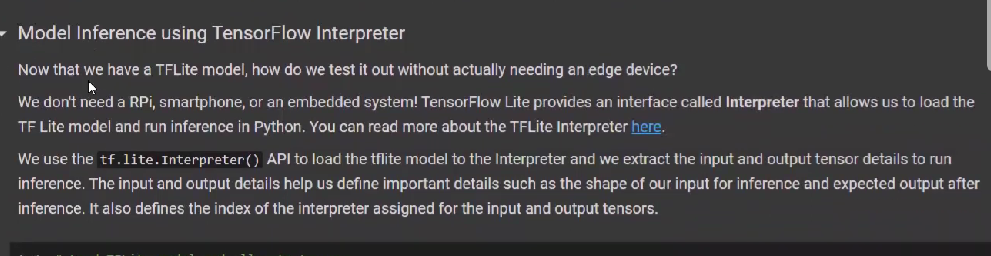

In [ ]:
# Step 2: Create a new TFLite interpreter

interpreter = tf.lite.Interpreter(model_content=tflite_model)

interpreter.allocate_tensors()

# Get input and output details
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


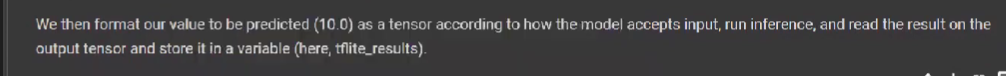

In [ ]:
# Give input
to_predict = np.array([[5.5]], dtype=np.float32)

interpreter.set_tensor(input_details[0]['index'], to_predict)

# Run inference
interpreter.invoke()

# Get output
tflite_results = interpreter.get_tensor(output_details[0]['index'])

print("TFLite prediction:", tflite_results)

TFLite prediction: [[14.008007]]
